# Pemrosesan Data KBJI 2014 untuk Analisis SC-WEAT

Notebook ini mengekstrak Golongan Pokok 2 Profesional dari PDF KBJI 2014. Target analisis adalah Jabatan berkode enam digit. Data lengkap dipertahankan bersama audit eksklusi. Analisis mengukur asosiasi intrinsik dalam embedding, bukan diskriminasi atau kondisi sosial nyata.

## 1. Import dan konfigurasi

Batas halaman dicari dari heading Golongan Pokok 2 sampai heading berikutnya Golongan Pokok 3.

In [1]:
import re
import sys
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import pdfplumber
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)
ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
PDF_PATH = DATA_DIR / "KBJI 2014.pdf"
FULL_OUTPUT = DATA_DIR / "test_kbji_profesional_all.csv"
ANALYSIS_OUTPUT = DATA_DIR / "test_kbji_profesional_analysis.csv"
assert PDF_PATH.exists()
print("Python:", sys.version.split()[0], "| PDF bytes:", PDF_PATH.stat().st_size)

Python: 3.13.15 | PDF bytes: 34550550


## 2. Ekstraksi hierarki dari isi PDF

Marker Golongan, Subgolongan, dan Jabatan digunakan sebagai konteks kode. Parent ditentukan dari awalan kode Jabatan.

In [2]:
def compact(value):
    return re.sub(r"\s+", " ", str(value)).strip()

with pdfplumber.open(PDF_PATH) as pdf:
    page_texts = [page.extract_text() or "" for page in pdf.pages]

start_page = next(i + 1 for i, text in enumerate(page_texts)
                  if re.search(r"(?m)^Golongan Pokok$\s*\n^2\s+PROFESIONAL\s*$", text, re.I))
stop_page = start_page + next(i for i, text in enumerate(page_texts[start_page:], start=1)
                              if re.search(r"(?m)^Golongan Pokok 3\s*$", text, re.I)) - 1
print({"start_page_pdf": start_page, "last_page_in_scope": stop_page,
       "first_page_outside_scope": stop_page + 1})

p2 = re.compile(r"^(\d{2})\s+(.+)$")
p3 = re.compile(r"^(\d{3})\s+(.+)$")
p4 = re.compile(r"^(\d{4})\s+(.+)$")
p6 = re.compile(r"^(\d{4}\.\d{2})\s+(.+)$")
major_groups, groups, subgroups, occupations = {}, {}, {}, {}
major_groups, groups, subgroups = {}, {}, {}
occupations = []
marker = None

for page_number in range(start_page, stop_page + 1):
    page_text = page_texts[page_number - 1]
    for raw_line in page_text.splitlines():
        line = compact(raw_line)
        if line in {"Golongan", "Subgolongan", "Jabatan"}:
            marker = line
            continue
        match = p6.match(line)
        if marker == "Jabatan" and match:
            code, name = match.groups()
            printed = re.search(r"Halaman\s+(\d+)", page_text)
            occupations.append({"occupation_code": code, "occupation_name_raw": name,
                                "source_page_pdf": page_number,
                                "source_page_printed": printed.group(1) if printed else pd.NA})
            continue
        match = p4.match(line)
        if marker == "Subgolongan" and match:
            subgroups.setdefault(*match.groups())
            continue
        match = p3.match(line)
        if marker == "Golongan" and match:
            groups.setdefault(*match.groups())
            continue
        match = p2.match(line)
        if match and match.group(1) in {"21", "22", "23", "24", "25", "26"}:
            major_groups.setdefault(*match.groups())

print("Jabatan:", len(occupations), "| Subgolongan Pokok:", len(major_groups),
      "| Golongan:", len(groups), "| Subgolongan:", len(subgroups))
assert len(occupations) == 501
assert set(major_groups) == {"21", "22", "23", "24", "25", "26"}

{'start_page_pdf': 159, 'last_page_in_scope': 330, 'first_page_outside_scope': 331}
Jabatan: 501 | Subgolongan Pokok: 6 | Golongan: 27 | Subgolongan: 92


## 3. Tabel lengkap dan normalisasi konservatif

Nama asli dari PDF disimpan terpisah. Normalisasi hanya lowercase, spasi, penanda Umum, dan tanda baca. Stemming dan stopword removal tidak dilakukan.

In [3]:
def normalize_occupation(value):
    text = unicodedata.normalize("NFKC", compact(value)).lower()
    text = re.sub(r"\(\s*umum\s*\)", " ", text)
    text = text.replace("/", " ")
    text = re.sub(r"[^\w\s-]", " ", text, flags=re.UNICODE)
    return compact(text)

df_all = pd.DataFrame(occupations)
df_all["major_group_code"] = "2"
df_all["major_group_name"] = "Profesional"
df_all["submajor_group_code"] = df_all.occupation_code.str[:2]
df_all["submajor_group_name"] = df_all.submajor_group_code.map(major_groups)
df_all["group_code"] = df_all.occupation_code.str[:3]
df_all["group_name"] = df_all.group_code.map(groups)
df_all["subgroup_code"] = df_all.occupation_code.str[:4]
df_all["subgroup_name"] = df_all.subgroup_code.map(subgroups)
df_all["occupation_text"] = df_all.occupation_name_raw.map(normalize_occupation)
df_all["token_count"] = df_all.occupation_text.str.split().str.len()
df_all = df_all[["major_group_code", "major_group_name", "submajor_group_code", "submajor_group_name",
    "group_code", "group_name", "subgroup_code", "subgroup_name", "occupation_code",
    "occupation_name_raw", "occupation_text", "source_page_pdf", "source_page_printed", "token_count"]]
display(df_all.head())
display(df_all[["occupation_name_raw", "occupation_text"]].head(12))
display(df_all.dtypes.rename("dtype").to_frame())
display(df_all.isna().sum().rename("missing_count").to_frame())

,major_group_code,major_group_name,submajor_group_code,submajor_group_name,group_code,group_name,subgroup_code,subgroup_name,occupation_code,occupation_name_raw,occupation_text,source_page_pdf,source_page_printed,token_count
0,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,2111,Ahli Fisika dan Astronomi,2111.01,Ahli Fisika (Umum),ahli fisika,161,121,2
1,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,2111,Ahli Fisika dan Astronomi,2111.02,Ahli Fisika Nuklir,ahli fisika nuklir,161,121,3
2,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,2111,Ahli Fisika dan Astronomi,2111.03,Ahli Fisika Mekanika,ahli fisika mekanika,161,121,3
3,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,2111,Ahli Fisika dan Astronomi,2111.04,Ahli Fisika Panas,ahli fisika panas,161,121,3
4,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,2111,Ahli Fisika dan Astronomi,2111.05,Ahli Fisika Sinar,ahli fisika sinar,162,122,3


,occupation_name_raw,occupation_text
0,Ahli Fisika (Umum),ahli fisika
1,Ahli Fisika Nuklir,ahli fisika nuklir
2,Ahli Fisika Mekanika,ahli fisika mekanika
3,Ahli Fisika Panas,ahli fisika panas
4,Ahli Fisika Sinar,ahli fisika sinar
5,Ahli Fisika Suara,ahli fisika suara
6,Ahli Fisika Listrik Dan Magnit,ahli fisika listrik dan magnit
7,Ahli Fisika Elektronika,ahli fisika elektronika
8,Ahli Fisika Medis,ahli fisika medis
9,Ahli Astronomi,ahli astronomi


,dtype
major_group_code,str
major_group_name,str
submajor_group_code,str
submajor_group_name,str
group_code,str
group_name,str
subgroup_code,str
subgroup_name,str
occupation_code,str
occupation_name_raw,str


,missing_count
major_group_code,0
major_group_name,0
submajor_group_code,0
submajor_group_name,0
group_code,0
group_name,0
subgroup_code,0
subgroup_name,0
occupation_code,0
occupation_name_raw,0


## 4. Audit validitas, residual, dan lexical leakage

Residual dan nama yang memuat istilah atribut gender tetap berada di tabel lengkap dengan alasan eksklusi.

In [4]:
gender_terms = {"laki-laki", "perempuan", "pria", "wanita", "ayah", "ibu", "suami", "istri",
                "putra", "putri", "pemuda", "pemudi", "cowok", "cewek", "jejaka", "gadis"}
df_all["is_valid_code"] = df_all.occupation_code.str.fullmatch(r"\d{4}\.\d{2}") & df_all.submajor_group_code.isin(major_groups)
df_all["is_duplicate"] = df_all.occupation_code.duplicated(keep=False)
df_all["is_residual"] = df_all.occupation_code.str.endswith(".99") | df_all.occupation_name_raw.str.contains(r"lainnya|ybdi|ytdl", case=False, na=False)
df_all["contains_gender_attribute"] = df_all.occupation_text.map(lambda x: bool(set(x.split()) & gender_terms))
df_all["hierarchy_complete"] = df_all[["submajor_group_name", "group_name", "subgroup_name"]].notna().all(axis=1)
df_all["name_nonempty"] = df_all.occupation_text.ne("")
df_all["include_analysis"] = (df_all.is_valid_code & ~df_all.is_duplicate & ~df_all.is_residual &
                              ~df_all.contains_gender_attribute & df_all.hierarchy_complete & df_all.name_nonempty)

def exclusion_reason(row):
    reasons = []
    if not row.is_valid_code: reasons.append("kode tidak valid")
    if row.is_duplicate: reasons.append("kode duplikat")
    if row.is_residual: reasons.append("kategori residual")
    if row.contains_gender_attribute: reasons.append("lexical leakage atribut gender")
    if not row.hierarchy_complete: reasons.append("hierarki tidak lengkap")
    if not row.name_nonempty: reasons.append("nama kosong")
    return "; ".join(reasons)

df_all["exclusion_reason"] = df_all.apply(exclusion_reason, axis=1)
df_analysis = df_all[df_all.include_analysis].copy()
audit_summary = pd.DataFrame({
    "metric": ["baris lengkap", "baris analisis", "residual", "lexical leakage", "duplikasi kode", "kode tidak valid"],
    "value": [len(df_all), len(df_analysis), int(df_all.is_residual.sum()), int(df_all.contains_gender_attribute.sum()),
              int(df_all.is_duplicate.sum()), int((~df_all.is_valid_code).sum())],
})
display(audit_summary)
display(df_all.exclusion_reason.replace("", "termasuk analisis").value_counts().rename_axis("reason").to_frame("count"))
assert df_all.occupation_code.is_unique and len(df_analysis) > 0

,metric,value
0,baris lengkap,501
1,baris analisis,415
2,residual,85
3,lexical leakage,1
4,duplikasi kode,0
5,kode tidak valid,0


,count
reason,
termasuk analisis,415
kategori residual,85
lexical leakage atribut gender,1


## 5. Pemeriksaan hierarki dan visualisasi

,level,unique_code_count
0,Golongan Pokok,1
1,Subgolongan Pokok,6
2,Golongan,27
3,Subgolongan,92
4,Jabatan,501


,submajor_group_code,occupation_count,analysis_count
0,21,161,138
1,22,89,74
2,23,52,42
3,24,38,29
4,25,34,26
5,26,127,106


,occupation_count
group_code,
211,28
212,8
213,28
214,52
215,13
216,32
221,22
222,9
223,7


,occupation_code,occupation_name_raw,exclusion_reason
10,2111.99,Ahli Fisika dan Astronomi Lainnya,kategori residual
15,2112.99,Ahli Meteorologi dan Klimatologi Lainnya,kategori residual
21,2113.99,Ahli Kimia Lainnya,kategori residual
27,2114.99,Ahli Geologi Dan Geofisika Lainnya,kategori residual
35,2120.99,"Ahli Matematika, Aktuaria Dan Statistika Lainnya",kategori residual
49,2131.99,"Ahli Biologi, Botani, Zoologi dan YBDI Lainnya",kategori residual
55,2132.99,"Penasihat Pertanian, Kehutanan dan Perikanan L...",kategori residual
63,2133.99,Ahli Perlindungan Lingkungan Lainnya,kategori residual
69,2141.99,Ahli Teknik Industri dan Produksi Lainnya,kategori residual
79,2142.99,Ahli Teknik Sipil Lainnya,kategori residual


,occupation_code,occupation_name_raw,exclusion_reason
422,2635.09,Organisator Kesejahteraan Perempuan,lexical leakage atribut gender


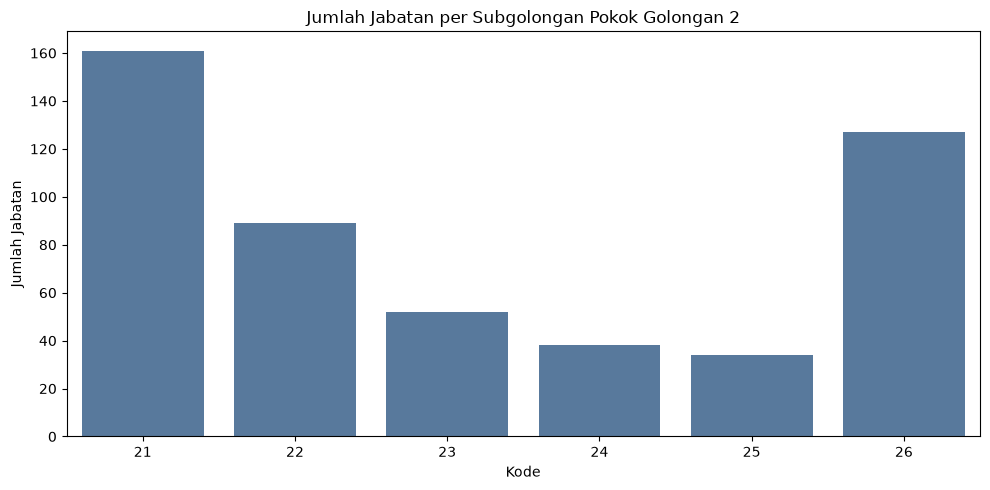

In [5]:
hierarchy_counts = pd.DataFrame({
    "level": ["Golongan Pokok", "Subgolongan Pokok", "Golongan", "Subgolongan", "Jabatan"],
    "unique_code_count": [df_all.major_group_code.nunique(), df_all.submajor_group_code.nunique(),
                          df_all.group_code.nunique(), df_all.subgroup_code.nunique(), df_all.occupation_code.nunique()],
})
display(hierarchy_counts)
display(df_all.groupby("submajor_group_code").agg(occupation_count=("occupation_code", "count"),
                                                  analysis_count=("include_analysis", "sum")).reset_index())
display(df_all.groupby("group_code").size().rename("occupation_count").to_frame())
display(df_all[df_all.is_residual][["occupation_code", "occupation_name_raw", "exclusion_reason"]].head(10))
display(df_all[df_all.contains_gender_attribute][["occupation_code", "occupation_name_raw", "exclusion_reason"]])
fig, ax = plt.subplots(figsize=(10, 5))
counts = df_all.groupby(["submajor_group_code", "submajor_group_name"]).size().reset_index(name="occupation_count")
sns.barplot(data=counts, x="submajor_group_code", y="occupation_count", color="#4C78A8", ax=ax)
ax.set(title="Jumlah Jabatan per Subgolongan Pokok Golongan 2", xlabel="Kode", ylabel="Jumlah Jabatan")
plt.tight_layout(); plt.show()

## 6. Menyimpan data hasil ekstraksi

In [6]:
df_all.to_csv(FULL_OUTPUT, index=False, encoding="utf-8")
df_analysis.to_csv(ANALYSIS_OUTPUT, index=False, encoding="utf-8")
print(FULL_OUTPUT, FULL_OUTPUT.stat().st_size, "bytes")
print(ANALYSIS_OUTPUT, ANALYSIS_OUTPUT.stat().st_size, "bytes")
display(pd.read_csv(FULL_OUTPUT).head())
display(pd.read_csv(ANALYSIS_OUTPUT).head())

E:\SEMESTER 7 (SKRIPSI)\skripsi-weat\data\test_kbji_profesional_all.csv 115968 bytes
E:\SEMESTER 7 (SKRIPSI)\skripsi-weat\data\test_kbji_profesional_analysis.csv 92909 bytes


,major_group_code,major_group_name,submajor_group_code,submajor_group_name,group_code,group_name,subgroup_code,subgroup_name,occupation_code,occupation_name_raw,...,source_page_printed,token_count,is_valid_code,is_duplicate,is_residual,contains_gender_attribute,hierarchy_complete,name_nonempty,include_analysis,exclusion_reason
0,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,2111,Ahli Fisika dan Astronomi,2111.01,Ahli Fisika (Umum),...,121,2,True,False,False,False,True,True,True,NaN
1,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,2111,Ahli Fisika dan Astronomi,2111.02,Ahli Fisika Nuklir,...,121,3,True,False,False,False,True,True,True,NaN
2,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,2111,Ahli Fisika dan Astronomi,2111.03,Ahli Fisika Mekanika,...,121,3,True,False,False,False,True,True,True,NaN
3,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,2111,Ahli Fisika dan Astronomi,2111.04,Ahli Fisika Panas,...,121,3,True,False,False,False,True,True,True,NaN
4,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,2111,Ahli Fisika dan Astronomi,2111.05,Ahli Fisika Sinar,...,122,3,True,False,False,False,True,True,True,NaN


,major_group_code,major_group_name,submajor_group_code,submajor_group_name,group_code,group_name,subgroup_code,subgroup_name,occupation_code,occupation_name_raw,...,source_page_printed,token_count,is_valid_code,is_duplicate,is_residual,contains_gender_attribute,hierarchy_complete,name_nonempty,include_analysis,exclusion_reason
0,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,2111,Ahli Fisika dan Astronomi,2111.01,Ahli Fisika (Umum),...,121,2,True,False,False,False,True,True,True,NaN
1,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,2111,Ahli Fisika dan Astronomi,2111.02,Ahli Fisika Nuklir,...,121,3,True,False,False,False,True,True,True,NaN
2,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,2111,Ahli Fisika dan Astronomi,2111.03,Ahli Fisika Mekanika,...,121,3,True,False,False,False,True,True,True,NaN
3,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,2111,Ahli Fisika dan Astronomi,2111.04,Ahli Fisika Panas,...,121,3,True,False,False,False,True,True,True,NaN
4,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,2111,Ahli Fisika dan Astronomi,2111.05,Ahli Fisika Sinar,...,122,3,True,False,False,False,True,True,True,NaN


## 7. Validasi akhir Notebook 1

In [7]:
validation_processing = pd.DataFrame([
    {"check_name": "501 Jabatan hasil ekstraksi", "expected": 501, "observed": len(df_all), "status": "PASS" if len(df_all) == 501 else "FAIL", "notes": "checkpoint isi PDF"},
    {"check_name": "6 Subgolongan Pokok", "expected": 6, "observed": df_all.submajor_group_code.nunique(), "status": "PASS" if df_all.submajor_group_code.nunique() == 6 else "FAIL", "notes": "kode 21 sampai 26"},
    {"check_name": "kode Jabatan unik", "expected": True, "observed": df_all.occupation_code.is_unique, "status": "PASS" if df_all.occupation_code.is_unique else "FAIL", "notes": "audit duplikasi"},
    {"check_name": "CSV tersedia", "expected": True, "observed": FULL_OUTPUT.exists() and ANALYSIS_OUTPUT.exists(), "status": "PASS" if FULL_OUTPUT.exists() and ANALYSIS_OUTPUT.exists() else "FAIL", "notes": "UTF-8"},
])
display(validation_processing)
assert (validation_processing.status == "PASS").all()

,check_name,expected,observed,status,notes
0,501 Jabatan hasil ekstraksi,501,501,PASS,checkpoint isi PDF
1,6 Subgolongan Pokok,6,6,PASS,kode 21 sampai 26
2,kode Jabatan unik,True,True,PASS,audit duplikasi
3,CSV tersedia,True,True,PASS,UTF-8
